<a href="https://colab.research.google.com/github/devaramanelohith/ai-agents-cookbook/blob/main/langgraph/Langgraph_states_and_nodes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creating a Simple Graph

In [2]:
from typing import TypedDict, List
class State(TypedDict): # Define the structure of the state
    name: str # vinay
    primary_email: str # vinay@gmail.com
    alt_emails: List[str] # vina1@gmail.com, vin2@gmail.com


In [3]:
#Node 1 - Collect
def collect_name_and_primary_email(state:State):
  name = input("Enter your name:")
  email = input("Enter your primary email:")

  return {
      "name": name,
      "primary_email": email
  }

In [4]:
# Node 2: Collect two alternative email address
def collect_alternative_emails(state:State):
  print("\nEnter two alternative email IDs")

  email1 = input("Enter Alternatve Email 1:")
  email2 = input("Enter Alternative Email2:")

  return{
      "alt_emails":[email1,email2]
  }

In [5]:
# Node 3: Display a summary of the collected information
def summary(state: State):
    print("\nRegistration Summary")
    print("Name:", state["name"])
    print("Primary Email:", state["primary_email"])
    print("Alternative Emails:", state["alt_emails"])
    return state

In [6]:
!pip install langgraph langchain

Enter your name:Lohith
Enter your primary email:loh@gmail.com

Enter two alternative email IDs
Enter Alternatve Email 1:loh1@gmail.com
Enter Alternative Email2:loh2@gmail.com

Registration Summary
Name: Lohith
Primary Email: loh@gmail.com
Alternative Emails: ['loh1@gmail.com', 'loh2@gmail.com']


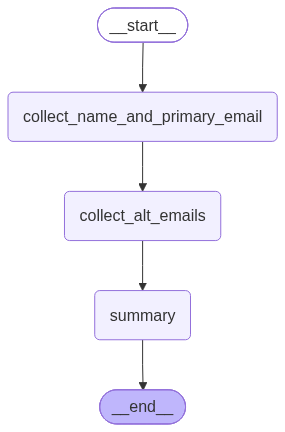

In [7]:
from langgraph.graph import StateGraph, END, START
# Create a graph using the defined State structure
builder = StateGraph(State)
builder.add_node("collect_name_and_primary_email", collect_name_and_primary_email)
builder.add_node("collect_alt_emails",collect_alternative_emails)
builder.add_node("summary",summary)

builder.set_entry_point("collect_name_and_primary_email")

builder.add_edge("collect_name_and_primary_email","collect_alt_emails")
builder.add_edge("collect_alt_emails","summary")

builder.add_edge("summary",END)

graph = builder.compile()

graph.invoke({})
from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

Conditional Routing

Enter your name: Lohith
Enter your email: loh@gmail.com
Do you wish to enter your phone number? (yes/no) no

Registration Summary
Name: Lohith
Email: loh@gmail.com
Phone: Not Provided


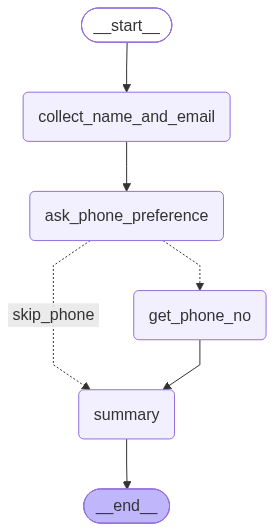

In [8]:
# State
class State(TypedDict): # Define the structure of the state
    name: str # vinay
    email: str #  vina@gmail,com
    consent_phone: str # no
    phone_no: str



# Nodes
# Node 1: Collect user's name and email
def collect_name_and_email(state: State):
    name = input("Enter your name: ")
    email = input("Enter your email: ")

    return {
        "name": name,
        "email": email
    }


# Node 2: Ask user if they want to provide their phone number
def ask_phone_preference(state: State):
    consent = input("Do you wish to enter your phone number? (yes/no) ")
    return {"consent_phone": consent.lower()}


# Node 3: Collect phone number if user agreed
def get_phone_no(state: State):
    phone_no = input("Please enter your phone number: ")
    return {"phone_no": phone_no}


# Node 4: Display a summary of collected information
def summary(state: State):
    print("\nRegistration Summary")
    print("Name:", state["name"])
    print("Email:", state["email"])

    if state.get("phone_no"):
        print("Phone:", state["phone_no"])
    else:
        print("Phone: Not Provided")
    return state



# Condition Function
# Decides which node to go to next based on user's consent
def route_phone(state: State):

    if state["consent_phone"] == "yes":
        return "get_phone_no"

    return "skip_phone"



# Graph
builder = StateGraph(State)

# Add nodes to the graph
builder.add_node("collect_name_and_email", collect_name_and_email)
builder.add_node("ask_phone_preference", ask_phone_preference)
builder.add_node("get_phone_no", get_phone_no)
builder.add_node("summary", summary)

# Define the starting node
builder.set_entry_point("collect_name_and_email")

# Define flow between nodes
builder.add_edge("collect_name_and_email", "ask_phone_preference")


# Add conditional branching based on user's answer
builder.add_conditional_edges(
    "ask_phone_preference",
    route_phone,  # get_phone_no skip_phone
    {
        "get_phone_no": "get_phone_no", # builder.add_edge("ask_phone_preference", "get_phone_no")
        "skip_phone": "summary" # builder.add_edge("ask_phone_preference", "summary")
    }
)

# After collecting phone, move to summary
builder.add_edge("get_phone_no", "summary")

# End the graph after summary
builder.add_edge("summary", END)

# Compile the graph
graph = builder.compile()

# Run
graph.invoke({})

# Visualization
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

Looping Workflow

Please enter your phone number: 9123456789
Valid Phone Number
{'phone_no': '9123456789'}


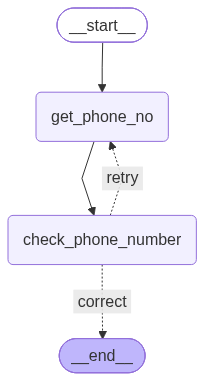

In [9]:
# State
class State(TypedDict): # Define the structure of the state
    phone_no: int


# Nodes
# Node 1: Ask the user to enter their phone number
def get_phone_no(state: State):

    phone_no = input("Please enter your phone number: ")
    return {
        "phone_no": phone_no,
    }

# Node 2: Check whether the phone number is valid
def check_phone_number(state: State):

    if len(state["phone_no"]) == 10:
        print("Valid Phone Number")
    else:
        print("Invalid Phone number, enter 10 digits...")

    return state

# Condition
# Decides whether to end the graph or retry input
def should_continue(state: State):

    if len(state["phone_no"]) == 10:
        return "correct"
    else:
        return "retry"
    return state

# Graph
builder = StateGraph(State)

# Add nodes to the graph
builder.add_node("get_phone_no", get_phone_no)
builder.add_node("check_phone_number", check_phone_number)

# Define the starting node
builder.set_entry_point("get_phone_no")

# Define normal flow
builder.add_edge("get_phone_no","check_phone_number")

# Add conditional routing after validation
builder.add_conditional_edges(
    "check_phone_number",
    should_continue,
    {
        "correct": END,
        "retry": "get_phone_no"
    }
)

# Compile the graph
graph = builder.compile()


# Run
result = graph.invoke({})
print(result)


# Visualization
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))